In [1]:
import pickle
from dataclasses import dataclass
from itertools import product
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from IPython.display import display, SVG


COLOR_DICT = {
    "desmin": "#CC3311",
    "actin": "#0077BB",
    "actinin": "#009988",
    "myosin": "#BBBBBB",
}

In [ ]:
def _corners(bounds):
    return np.asarray(list(product(*np.asarray(bounds).reshape(3, 2))), dtype=float)


def _default_edges(bounds):
    x0, x1, y0, y1, z0, z1 = bounds
    # Edges match the supplied view: X along the front bottom, Y along the
    # left top, and Z connecting their origins at the front-left corner.
    return {
        "x": np.array([[x0, y0, z0], [x1, y0, z0]]),
        "y": np.array([[x0, y0, z1], [x0, y1, z1]]),
        "z": np.array([[x0, y0, z0], [x0, y0, z1]]),
    }


def _grid_segments(bounds, ticks, camera_position, show_box):
    bounds = np.asarray(bounds).reshape(3, 2)
    center = bounds.mean(axis=1)
    # Draw grid planes on the side farthest from the camera. Because these
    # lines are 3D actors, the surfaces can occlude them naturally.
    back = np.where(
        np.asarray(camera_position[0]) >= center, bounds[:, 0], bounds[:, 1]
    )
    segments = []
    for fixed in range(3):
        other = [a for a in range(3) if a != fixed]
        for tick_axis, line_axis in (other, other[::-1]):
            for value in ticks["xyz"[tick_axis]]:
                points = np.tile(back, (2, 1))
                points[:, fixed] = back[fixed]
                points[:, tick_axis] = value
                points[:, line_axis] = bounds[line_axis]
                segments.append(points)
    if show_box:
        for direction in range(3):
            other = [a for a in range(3) if a != direction]
            for values in product(*bounds[other]):
                points = np.zeros((2, 3))
                points[:, direction] = bounds[direction]
                points[:, other] = values
                segments.append(points)
    # Remove duplicate edges where grid planes meet.
    unique = {}
    for segment in segments:
        key = tuple(sorted(tuple(p) for p in segment))
        unique[key] = segment
    return np.asarray(list(unique.values()))


@dataclass
class RenderedSkeletonPanel:
    image: np.ndarray
    bounds: tuple
    scene_bounds: tuple
    ticks: dict
    world_to_clip: np.ndarray
    camera_position: tuple
    colors: dict

    def project(self, xyz):
        """World XYZ -> screenshot pixels, with Y increasing upward."""
        xyz = np.atleast_2d(np.asarray(xyz, dtype=float))
        clip = np.column_stack((xyz, np.ones(len(xyz)))) @ self.world_to_clip.T
        if np.any(clip[:, 3] <= 0):
            raise ValueError("A requested annotation lies behind the camera.")
        h, w = self.image.shape[:2]
        return (clip[:, :2] / clip[:, 3, None] + 1) * np.array([w, h]) / 2


def load_skeleton_voxels(path):
    """Load a PyVista dataset pickled by the user's own mesh.save() call.

    That writer serializes the DataObject using pickle.dump. Reading explicitly
    avoids relying on version-specific .pkl handling inside pv.read(). This
    loader is intended only for the trusted source files created by the user.
    It does not extract surfaces, smooth, resample, or change coordinates.
    """
    import pyvista as pv

    with Path(path).open("rb") as handle:
        dataset = pickle.load(handle)
    if not isinstance(dataset, pv.DataSet):
        raise TypeError(
            f"Expected a saved PyVista dataset; found {type(dataset).__name__}."
        )
    if (
        dataset.n_points == 0
        or dataset.n_cells == 0
        or not np.isfinite(dataset.points).all()
    ):
        raise ValueError(
            "The saved voxel dataset must contain finite points and nonempty cells."
        )
    return dataset


def render_skeleton_panel(
    desmin_pkl,
    actinin_pkl,
    *,
    colors=None,
    bounds=None,
    xticks=None,
    yticks=None,
    zticks=None,
    window_size=(1600, 1600),
    azimuth=230,
    elevation=10,
    zoom=1.0,
    camera_position=None,
    parallel_projection=False,
    voxel_opacity=1.0,
    anti_aliasing="ssaa",
    lighting=True,
    grid_color="#777777",
    grid_linewidth=0.7,
    show_grid=True,
    show_box=True,
):
    """Load skeleton voxel cells and render without native numeric axis labels.

    Coordinates and cell geometry are preserved. Voxels are opaque by default,
    as in add_mesh in the original code; volume opacity curves do not apply.
    Each dataset is rendered directly with style='surface', smooth_shading=False
    and its assigned protein color. No tubes, enlarged points, or smoothing
    filters are used. Set anti_aliasing=None to retain the plotter's default AA.
    lighting=False is available for uniformly colored voxel faces.
    bounds optionally sets (xmin,xmax,ymin,ymax,zmin,zmax) for the displayed
    frame. The camera still includes the complete meshes. Ticks default to
    five values on X/Y and two on Z.

    Default camera: isometric start, azimuth=230 and elevation=10 degrees,
    perspective projection. For an exact match to an existing interactive
    view, pass camera_position=p.camera_position from that plot. This overrides
    azimuth/elevation/zoom. The returned object can be composed repeatedly.
    """
    import pyvista as pv

    colors = {**COLOR_DICT, **(colors or {})}
    if not np.isfinite(voxel_opacity) or not 0 <= voxel_opacity <= 1:
        raise ValueError("voxel_opacity must be between 0 and 1.")
    if anti_aliasing not in (None, "ssaa", "msaa", "fxaa"):
        raise ValueError("anti_aliasing must be None, 'ssaa', 'msaa' or 'fxaa'.")
    if not np.isfinite(zoom) or zoom <= 0:
        raise ValueError("zoom must be positive.")
    meshes = {
        "desmin": load_skeleton_voxels(desmin_pkl),
        "actinin": load_skeleton_voxels(actinin_pkl),
    }
    mesh_bounds = np.asarray([mesh.bounds for mesh in meshes.values()]).reshape(2, 3, 2)
    union = np.column_stack(
        (mesh_bounds[:, :, 0].min(axis=0), mesh_bounds[:, :, 1].max(axis=0))
    )
    limits = (
        union.copy()
        if bounds is None
        else np.asarray(bounds, dtype=float).reshape(3, 2)
    )
    if not np.isfinite(limits).all() or np.any(limits[:, 1] <= limits[:, 0]):
        raise ValueError("bounds must contain finite increasing X, Y and Z pairs.")
    scene_bounds = np.column_stack(
        (np.minimum(union[:, 0], limits[:, 0]), np.maximum(union[:, 1], limits[:, 1]))
    ).ravel()
    ticks = {}
    for axis, interval, supplied, count in zip(
        "xyz", limits, (xticks, yticks, zticks), (5, 5, 2)
    ):
        values = (
            np.linspace(*interval, count)
            if supplied is None
            else np.asarray(supplied, dtype=float)
        )
        if (
            values.ndim != 1
            or values.size == 0
            or not np.isfinite(values).all()
            or np.any(np.diff(values) <= 0)
            or values.min() < interval[0] - 1e-9
            or values.max() > interval[1] + 1e-9
        ):
            raise ValueError(
                f"{axis}ticks must increase and lie within the displayed bounds."
            )
        ticks[axis] = values
    p = pv.Plotter(off_screen=True, window_size=window_size)
    try:
        if anti_aliasing is not None:
            p.enable_anti_aliasing(anti_aliasing)
        for name, mesh in meshes.items():
            p.add_mesh(
                mesh,
                color=colors[name],
                opacity=voxel_opacity,
                style="surface",
                smooth_shading=False,
                split_sharp_edges=False,
                show_edges=False,
                lighting=True,
                ambient=0.5,
                diffuse=0.5,
                specular=0.0,
                show_scalar_bar=False,
                reset_camera=False,
            )
        p.set_background("black")
        if parallel_projection:
            p.enable_parallel_projection()
        else:
            p.disable_parallel_projection()
        if camera_position is None:
            p.view_isometric()
            # Use the complete frame for initial fitting, then retain the
            # original order of the user's azimuth/elevation adjustments.
            p.reset_camera(bounds=tuple(scene_bounds))
            p.camera.azimuth = azimuth
            p.camera.elevation = elevation
            p.camera.zoom(zoom)
        else:
            p.camera_position = camera_position
        cpos = tuple(tuple(v) for v in p.camera_position)
        segments = _grid_segments(limits.ravel(), ticks, cpos, show_box)
        if not show_grid:
            segments = _grid_segments(
                limits.ravel(), {a: [] for a in "xyz"}, cpos, show_box
            )
        if len(segments):
            points = segments.reshape(-1, 3)
            connectivity = np.column_stack(
                (np.full(len(segments), 2), np.arange(len(points)).reshape(-1, 2))
            ).ravel()
            wire = pv.PolyData(points, lines=connectivity)
            p.add_mesh(
                wire,
                color=grid_color,
                line_width=grid_linewidth,
                lighting=False,
                show_scalar_bar=False,
                reset_camera=False,
            )
        p.reset_camera_clipping_range()
        rgb = np.array(p.screenshot(transparent_background=False), copy=True)
        m = p.camera.GetCompositeProjectionTransformMatrix(
            p.renderer.GetTiledAspectRatio(), -1, 1
        )
        matrix = np.array([[m.GetElement(i, j) for j in range(4)] for i in range(4)])
    finally:
        p.close()
    return RenderedSkeletonPanel(
        rgb, tuple(limits.ravel()), tuple(scene_bounds), ticks, matrix, cpos, colors
    )


def compose_skeleton_panel(
    rendered,
    *,
    scene_width=3.6,
    figsize=None,
    margins=(1.20, 0.22, 0.58, 0.25),
    tick_fontsize=11,
    axis_fontsize=14,
    tick_format=".1f",
    tick_pads=None,
    label_pads=None,
    tick_rotations=None,
    label_rotations=None,
    tick_offsets=None,
    label_offsets=None,
    tick_length=3,
    axis_linewidth=0.8,
    axis_color="#DDDDDD",
    axis_edges=None,
    resolve_collisions=True,
    font_family="DejaVu Sans",
):
    """Compose a calibrated raster scene with vector 3D axes and labels.

    scene_width, figsize and margins=(left,right,bottom,top) are inches.
    Padding, offsets, linewidths and tick_length are points. Font sizes are
    points. No 3D geometry or projected scale is stretched by the composition.

    tick_pads defaults to {'x':12, 'y':12, 'z':34}; Z numbers are separated
    from the Y-origin label. label_pads defaults to {'x':35,'y':35,'z':65}.
    tick_rotations defaults to projected X/Y directions, with horizontal Z
    numbers. Each can be overridden by a dict keyed 'x', 'y', 'z'.
    label_rotations similarly overrides the projected axis-title angles.
    tick_offsets accepts extra (dx,dy) point offsets keyed by (axis,index),
    e.g. {('z',0):(-3,-2)}. label_offsets accepts the same offsets per axis.

    resolve_collisions nudges crowded numeric labels outward using their
    rendered text bounds; tick marks remain at their exact projected positions.
    axis_edges optionally supplies two XYZ endpoints per axis for other views.
    The default edge choices reproduce the supplied azimuth/elevation view.
    """
    tick_pads = {"x": 12, "y": 12, "z": 34, **(tick_pads or {})}
    label_pads = {"x": 35, "y": 35, "z": 65, **(label_pads or {})}
    tick_offsets, label_offsets = tick_offsets or {}, label_offsets or {}
    edges = _default_edges(rendered.bounds) if axis_edges is None else axis_edges
    frame = rendered.project(_corners(rendered.scene_bounds))
    h, w = rendered.image.shape[:2]
    if np.any(frame < 1) or np.any(frame > np.array([w, h]) - 1):
        raise ValueError(
            "The scene touches the screenshot edge. Render again with a smaller zoom."
        )
    x0, y0 = np.floor(frame.min(axis=0) - 1)
    x1, y1 = np.ceil(frame.max(axis=0) + 1)
    image = rendered.image[h - int(y1) : h - int(y0), int(x0) : int(x1)]
    ratio = (y1 - y0) / (x1 - x0)
    left, right, bottom, top = map(float, margins)
    if min(left, right, bottom, top) < 0 or scene_width <= 0:
        raise ValueError("Margins must be nonnegative and scene_width positive.")
    if figsize is None:
        sw, sh = scene_width, scene_width * ratio
        fw, fh = left + sw + right, bottom + sh + top
        sx, sy = left, bottom
    else:
        fw, fh = map(float, figsize)
        available_w, available_h = fw - left - right, fh - bottom - top
        if min(available_w, available_h) <= 0:
            raise ValueError("figsize is too small for the margins.")
        sw = min(available_w, available_h / ratio)
        sh = sw * ratio
        sx, sy = left + (available_w - sw) / 2, bottom + (available_h - sh) / 2
    center = rendered.project(np.asarray(rendered.bounds).reshape(3, 2).mean(axis=1))[0]
    artists = {"ticks": {}, "labels": {}, "axis_lines": {}, "adjusted_ticks": []}
    with (
        plt.style.context("default"),
        mpl.rc_context(
            {
                "font.family": font_family,
                "figure.autolayout": False,
                "figure.constrained_layout.use": False,
            }
        ),
    ):
        fig = plt.figure(figsize=(fw, fh), facecolor="black")
        ax = fig.add_axes([sx / fw, sy / fh, sw / fw, sh / fh], facecolor="black")
        ax.imshow(
            image,
            extent=(x0, x1, y0, y1),
            origin="upper",
            aspect="equal",
            interpolation="none",
        )
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_autoscale_on(False)
        ax.set_axis_off()
        raw_per_point = (x1 - x0) / (sw * 72)
        numeric = []
        normals = {}
        for i, axis in enumerate("xyz"):
            edge = np.asarray(edges[axis], dtype=float)
            if (
                edge.shape != (2, 3)
                or not np.isfinite(edge).all()
                or edge[1, i] <= edge[0, i]
            ):
                raise ValueError(
                    f"{axis}: supply two finite XYZ endpoints with increasing {axis}."
                )
            other = [j for j in range(3) if j != i]
            if not np.allclose(edge[0, other], edge[1, other]):
                raise ValueError(f"{axis}: its edge must vary only along {axis}.")
            projected = rendered.project(edge)
            tangent = projected[1] - projected[0]
            length = np.linalg.norm(tangent)
            if length < 1e-8:
                raise ValueError(
                    f"{axis} axis is viewed end-on; choose a different camera."
                )
            tangent /= length
            normal = np.array([-tangent[1], tangent[0]])
            if normal @ (projected.mean(axis=0) - center) < 0:
                normal *= -1
            # Horizontal outward placement keeps the short Z ticks distinct.
            text_normal = np.array([-1.0, 0.0]) if axis == "z" else normal
            normals[axis] = text_normal
            angle = (np.degrees(np.arctan2(tangent[1], tangent[0])) + 90) % 180 - 90
            rotation = (tick_rotations or {}).get(axis, 0.0 if axis == "z" else angle)
            label_angle = (label_rotations or {}).get(
                axis,
                np.degrees(np.arctan2(tangent[1], tangent[0]))
                if axis == "z"
                else angle,
            )
            (line,) = ax.plot(
                *projected.T,
                color=axis_color,
                lw=axis_linewidth,
                clip_on=False,
                zorder=3,
            )
            artists["axis_lines"][axis] = line
            for index, value in enumerate(rendered.ticks[axis]):
                point = edge[0].copy()
                point[i] = value
                q = rendered.project(point)[0]
                inner = q - normal * tick_length * raw_per_point
                ax.plot(
                    [q[0], inner[0]],
                    [q[1], inner[1]],
                    color=axis_color,
                    lw=axis_linewidth,
                    clip_on=False,
                    zorder=4,
                )
                offset = text_normal * tick_pads[axis] + np.asarray(
                    tick_offsets.get((axis, index), (0, 0))
                )
                value = 0.0 if abs(value) < 1e-12 else value
                text = ax.annotate(
                    format(value, tick_format),
                    xy=q,
                    xytext=offset,
                    textcoords="offset points",
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=tick_fontsize,
                    rotation=rotation,
                    rotation_mode="anchor",
                    annotation_clip=False,
                    zorder=5,
                )
                artists["ticks"][(axis, index)] = text
                numeric.append((axis, index, text))
            midpoint = rendered.project(edge.mean(axis=0))[0]
            offset = text_normal * label_pads[axis] + np.asarray(
                label_offsets.get(axis, (0, 0))
            )
            text = ax.annotate(
                f"{axis} (μm)",
                xy=midpoint,
                xytext=offset,
                textcoords="offset points",
                ha="center",
                va="center",
                rotation=label_angle,
                rotation_mode="anchor",
                fontsize=axis_fontsize,
                color="white",
                annotation_clip=False,
                zorder=6,
            )
            artists["labels"][axis] = text
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        if resolve_collisions:
            accepted = []
            # Keep the long-axis labels stable; resolve the short-axis crowding last.
            for axis, index, text in numeric:
                for attempt in range(51):
                    bbox = text.get_window_extent(renderer).padded(1.5 * fig.dpi / 72)
                    if not any(bbox.overlaps(b) for b in accepted):
                        break
                    text.set_position(
                        np.asarray(text.get_position()) + 2 * normals[axis]
                    )
                else:
                    plt.close(fig)
                    raise ValueError(
                        """Tick labels remain crowded. Increase scene_width or reduce 
                        tick_fontsize."""
                    )
                if attempt:
                    artists["adjusted_ticks"].append((axis, index))
                accepted.append(
                    text.get_window_extent(renderer).padded(1.5 * fig.dpi / 72)
                )
            for axis, text in artists["labels"].items():
                for attempt in range(51):
                    bbox = text.get_window_extent(renderer).padded(2 * fig.dpi / 72)
                    if not any(bbox.overlaps(b) for b in accepted):
                        break
                    text.set_position(
                        np.asarray(text.get_position()) + 2 * normals[axis]
                    )
                else:
                    plt.close(fig)
                    raise ValueError(
                        """Axis labels remain crowded. Increase scene_width or reduce 
                        axis_fontsize."""
                    )
                accepted.append(
                    text.get_window_extent(renderer).padded(2 * fig.dpi / 72)
                )
        # Keep full-canvas exports honest: report undersized margins explicitly.
        fig.canvas.draw()
        for text in [*artists["ticks"].values(), *artists["labels"].values()]:
            bbox = text.get_window_extent(fig.canvas.get_renderer())
            if (
                bbox.x0 < 0
                or bbox.y0 < 0
                or bbox.x1 > fig.bbox.x1
                or bbox.y1 > fig.bbox.y1
            ):
                plt.close(fig)
                raise ValueError(
                    "Labels extend outside the canvas. Increase margins or figsize."
                )
    return fig, ax, artists

In [8]:
rendered = render_skeleton_panel(
    "../../source_data/fig_4/4d_desmin.pkl",
    "../../source_data/fig_4/4d_actinin.pkl",
    colors={
        "desmin": "#CC3311",
        "actinin": "#009988",
    },
    window_size=(2000, 2000),
    azimuth=230,
    elevation=10,
    anti_aliasing="ssaa",
    voxel_opacity=1.0,
)

In [9]:
fig, ax, artists = compose_skeleton_panel(
    rendered,
    scene_width=3.5,  # Inches, excluding margins
    figsize=None,  # Or specify (width, height)
    margins=(1.20, 0.22, 0.58, 0.25),
    tick_fontsize=11,
    axis_fontsize=14,
    tick_pads={"x": 12, "y": 12, "z": 34},
    label_pads={"x": 15, "y": 15, "z": 20},
    tick_rotations={"z": 0},
    resolve_collisions=True,
)

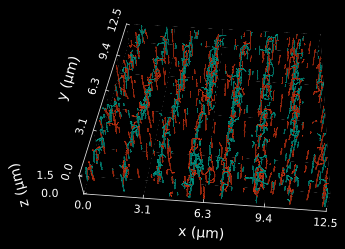

In [10]:
savepath = "../../figures/4d"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)